# Partie 1 — DCGAN sur Quick Draw (moutons)

Entraînement d'un DCGAN qui génère des dessins de moutons 28×28 en niveaux de gris, à partir du sous-ensemble *sheep* du jeu Quick Draw de Google (126 121 dessins).

Le notebook suit les étapes de l'énoncé :
1. Initialisation de l'environnement et des modules
2. Paramètres
3. Chargement et préparation des données
4. Modélisation, entraînement, sauvegarde
5. Génération à partir du modèle sauvegardé

## Étape 0 — Exécution sur Google Colab

Sur Colab, copier le dossier du projet (au minimum `modules/`) dans Google Drive sous `MyDrive/projet_genai`, puis choisir un environnement d'exécution GPU.
Si `QuickDraw/origine/sheep.npy` est absent, il est téléchargé depuis le dépôt public de Quick Draw. En local, cette cellule ne fait rien.

In [1]:
import sys, os

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    %cd /content/drive/MyDrive/projet_genai
    !pip install -q fidle

if not os.path.isfile('QuickDraw/origine/sheep.npy'):
    import urllib.request
    os.makedirs('QuickDraw/origine', exist_ok=True)
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/sheep.npy',
        'QuickDraw/origine/sheep.npy')

## Étape 1 — Initialisation de l'environnement et des modules

`fidle.init` crée le dossier de travail `./run/SHEEP1` et localise le dossier des données.
Il le lit dans la variable d'environnement `FIDLE_DATASETS_DIR`, que l'on fait pointer sur le dossier du projet.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from skimage import io
import time

sys.path.append(os.getcwd())
from modules.models import DCGAN
from modules.callbacks import ImagesCallback

import fidle

os.environ.setdefault('FIDLE_DATASETS_DIR', os.getcwd())
os.environ.setdefault('FIDLE_SAVE_FIGS', 'true')   # figures enregistrées dans run_dir/figs
run_id, run_dir, datasets_dir = fidle.init('SHEEP1')

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))

<br>**FIDLE - Environment initialization**

Version              : 3.0.1
Run id               : SHEEP1
Run dir              : ./run/SHEEP1
Datasets dir         : C:\Users\Ilyann\Desktop\app\projet_genai
Start time           : 23/11/26 00:44:42
Hostname             : PC-ILYANN (Windows)
Update keras cache   : False
Update torch cache   : False
Save figs            : ./run/SHEEP1/figs (True)
keras                : 2.10.0
numpy                : 1.26.4
sklearn              : 1.7.2
yaml                 : 6.0.4
skimage              : 0.25.2
matplotlib           : 3.10.9
pandas               : 2.3.3
TensorFlow : 2.10.1
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Étape 2 — Paramètres du projet

L'énoncé propose `scale=0.01, epochs=5` pour un test rapide et `scale=1, epochs=10` pour un résultat correct.
Ici, on utilise **tout le jeu de données** (`scale=1`). Le nombre d'epochs (10) est justifié à l'étape 4, à partir des courbes de perte et des images produites à chaque epoch.

`fit_verbosity=2` affiche une ligne par epoch au lieu d'une barre de progression : avec environ 3 900 batchs par epoch, la barre alourdit beaucoup le notebook.
La graine fixe rend l'entraînement reproductible sur une même machine. Sur GPU, certaines opérations restent non déterministes, donc deux exécutions peuvent légèrement différer.

In [3]:
latent_dim    = 128
scale         = 1
epochs        = 10
batch_size    = 32
num_img       = 12
fit_verbosity = 2
seed          = 42

keras.utils.set_random_seed(seed)

## Étape 3 — Chargement et préparation des données

Chaque ligne de `sheep.npy` contient un dessin de 784 pixels (28×28) codés en `uint8`. Le fond vaut 0 et les traits 255.

Préparation :
- **mélange** avant la sélection de `scale`, pour que le sous-ensemble ne dépende pas de l'ordre du fichier ;
- **redimensionnement** de (N, 784) vers (N, 28, 28, 1), la forme attendue par les convolutions ;
- **normalisation** dans [0, 1], qui correspond à la sortie *sigmoid* du générateur. Le discriminateur voit ainsi des images réelles et générées sur la même échelle.

Brut       : (126121, 784) uint8 min 0 max 255
Datasets have been resized with a factor  1


Préparé    : (126121, 28, 28, 1) float32 min 0.0 max 1.0
Pixels de trait (> 0.5) : 17.8%


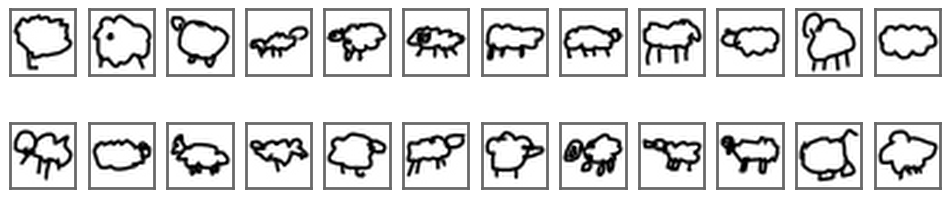

In [4]:
x_data = np.load(f'{datasets_dir}/QuickDraw/origine/sheep.npy')
print('Brut       :', x_data.shape, x_data.dtype, 'min', x_data.min(), 'max', x_data.max())

x_data = x_data[np.random.default_rng(seed).permutation(len(x_data))]
x_data = fidle.utils.rescale_dataset(x_data, scale=scale)
x_data = x_data.reshape(-1, 28, 28, 1).astype('float32') / 255.

print('Préparé    :', x_data.shape, x_data.dtype, 'min', x_data.min(), 'max', x_data.max())
print(f'Pixels de trait (> 0.5) : {(x_data > 0.5).mean():.1%}')

fidle.scrawler.images(x_data[:24], columns=12, x_size=1, y_size=1, save_as='01-dataset')

Les dessins sont très hétérogènes : moutons de face ou de profil, plus ou moins détaillés, parfois à peine reconnaissables. Le générateur doit couvrir cette variété, ce qui rend la tâche plus difficile que sur un jeu aux formes régulières.

## Étape 4 — Modélisation

### Générateur

Le générateur suit le schéma de l'énoncé : Dense → Reshape → (Upsample ×2 → Conv + ReLU) deux fois → Conv finale + Sigmoid.

- La couche Dense projette le vecteur latent sur une carte 7×7×128. Deux suréchantillonnages ×2 donnent 14×14 puis 28×28.
- Le nombre de filtres diminue quand la résolution augmente (128 puis 64), comme dans les DCGAN classiques. La couche la plus coûteuse, à 28×28, reste ainsi légère.
- `UpSampling2D` + `Conv2D` est préféré à `Conv2DTranspose`, qui produit facilement des artefacts en damier.
- La sigmoid finale borne les pixels dans [0, 1], comme les données.

In [5]:
def make_generator():
    inputs  = keras.Input(shape=(latent_dim,))
    x       = layers.Dense(7 * 7 * 128)(inputs)
    x       = layers.Reshape((7, 7, 128))(x)
    x       = layers.UpSampling2D()(x)
    x       = layers.Conv2D(128, kernel_size=3, padding='same')(x)
    x       = layers.ReLU()(x)
    x       = layers.UpSampling2D()(x)
    x       = layers.Conv2D(64, kernel_size=3, padding='same')(x)
    x       = layers.ReLU()(x)
    outputs = layers.Conv2D(1, kernel_size=5, padding='same', activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name='generator')

make_generator().summary()

Model: "generator"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 128)]             0         


 dense (Dense)               (None, 6272)              809088    


 reshape (Reshape)           (None, 7, 7, 128)         0         


... (9 outputs left out)

Total params: 1,032,065


Trainable params: 1,032,065


Non-trainable params: 0


_________________________________________________________________


### Discriminateur

Trois convolutions (noyau 5, pas 2) avec LeakyReLU(0.2) après chacune, puis Flatten + Dropout et une Dense sigmoid qui renvoie la probabilité que l'image soit réelle.

- Le pas de 2 réduit la résolution (28 → 14 → 7 → 4) sans pooling, comme dans l'article DCGAN.
- LeakyReLU garde un gradient non nul pour les entrées négatives. C'est important, car le générateur n'apprend qu'à travers les gradients du discriminateur.
- Le Dropout (0.2) est demandé par l'énoncé pour freiner le sur-apprentissage du discriminateur.

**Remarque.** Le `train_step` de la classe `DCGAN` fournie appelle les réseaux sans `training=True`. Le Dropout reste donc en mode inférence et **n'agit pas pendant l'entraînement**. Nous l'avons vérifié sous TensorFlow 2.10 et 2.21 : un `Dropout(0.9)` appelé dans ce `train_step` ne met aucune valeur à zéro. On garde la couche pour respecter l'architecture demandée. Le discriminateur est freiné autrement, par son taux d'apprentissage (voir plus bas).

In [6]:
def make_discriminator():
    inputs  = keras.Input(shape=(28, 28, 1))
    x       = layers.Conv2D(64,  kernel_size=5, strides=2, padding='same')(inputs)
    x       = layers.LeakyReLU(0.2)(x)
    x       = layers.Conv2D(128, kernel_size=5, strides=2, padding='same')(x)
    x       = layers.LeakyReLU(0.2)(x)
    x       = layers.Conv2D(256, kernel_size=5, strides=2, padding='same')(x)
    x       = layers.LeakyReLU(0.2)(x)
    x       = layers.Flatten()(x)
    x       = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name='discriminator')

make_discriminator().summary()

Model: "discriminator"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_2 (InputLayer)        [(None, 28, 28, 1)]       0         


 conv2d_3 (Conv2D)           (None, 14, 14, 64)        1664      


 leaky_re_lu (LeakyReLU)     (None, 14, 14, 64)        0         


... (7 outputs left out)

Total params: 1,030,145


Trainable params: 1,030,145


Non-trainable params: 0


_________________________________________________________________


### Compilation

Les deux réseaux sont assemblés dans la classe `DCGAN` fournie. Son `train_step` fait, à chaque batch :
1. une mise à jour du discriminateur sur un mélange d'images réelles (étiquette 1) et générées (étiquette 0) ;
2. une mise à jour du générateur avec de fausses étiquettes « réel » : il apprend à tromper le discriminateur.

Fonction de perte : entropie croisée binaire, la perte standard d'un GAN.

#### Choix des taux d'apprentissage

Le réglage habituel d'un DCGAN, Adam(2e-4, β₁ = 0.5) pour les deux réseaux (Radford et al., 2015), **ne fonctionne pas ici**. La cellule suivante le montre sur 300 batchs.

Les dessins réels sont surtout du fond noir (pixel moyen ≈ 0,18), alors que le générateur non entraîné produit un gris uniforme (≈ 0,5). Le premier indice que le discriminateur apprend est donc la luminosité. En suivant ce gradient, le générateur assombrit toute l'image et finit par produire des **images entièrement vides**. Sa sigmoid de sortie est alors saturée vers 0 et ne transmet presque plus de gradient : le générateur ne peut plus faire réapparaître de traits. Le discriminateur classe ensuite tout parfaitement, sa perte tombe à 0 et l'apprentissage s'arrête.

Nous avons obtenu le même effondrement avec Adam(1e-4), avec β₁ = 0.9, avec le lissage des étiquettes réelles (0,9) et avec un générateur à 256 filtres. Il apparaît à chaque fois en moins de 250 batchs.

Fidle DCGAN is ready :-)  latent dim = 128

Taux égaux (2e-4 / 2e-4) après 300 batchs : D(généré) moyen = 0.00019, pixels de trait = 0.0%


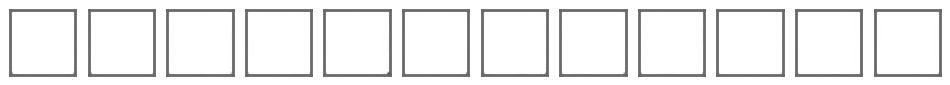

In [7]:
keras.utils.set_random_seed(seed)
control = DCGAN(discriminator=make_discriminator(), generator=make_generator(), latent_dim=latent_dim)
control.compile(
    discriminator_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5),
    generator_optimizer     = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5),
    loss_function           = keras.losses.BinaryCrossentropy()
)
control.fit(x_data[:300 * batch_size], epochs=1, batch_size=batch_size, verbose=0)

fake = control.generator.predict(np.random.normal(size=(12, latent_dim)), verbose=0)
print(f'Taux égaux (2e-4 / 2e-4) après 300 batchs : D(généré) moyen = {control.discriminator.predict(fake, verbose=0).mean():.5f}, '
      f'pixels de trait = {(fake > 0.5).mean():.1%}')
fidle.scrawler.images(fake, columns=12, x_size=1, y_size=1, save_as='02-collapse')

La solution retenue est de **ralentir le discriminateur** : taux de 2e-5 pour lui et de 2e-4 pour le générateur, soit un rapport de 10 (même idée que la *two time-scale update rule* de Heusel et al., 2017). Le discriminateur apprend alors assez lentement pour que le générateur ait le temps de placer des traits avant d'être pénalisé.

Pour choisir, nous avons comparé deux rapports sur 15 epochs :
- **D = 5e-5** : de bonnes images, mais le discriminateur prend lentement le dessus (sa perte baisse à chaque epoch) ;
- **D = 2e-5** : les deux pertes restent près de ln 2 ≈ 0,693, l'équilibre théorique où D ne distingue plus réel et généré. C'est ce réglage qui est conservé.

Autre solution efficace : ajouter une BatchNormalization dans le générateur. Elle impose toutefois de modifier le `train_step` fourni pour passer `training=True`, sinon elle reste en mode inférence. On l'écarte pour garder le module et l'architecture de l'énoncé tels quels.

β₁ = 0.5 (au lieu de 0.9) réduit l'élan d'Adam, qui gêne quand la cible change à chaque pas, comme dans un GAN.

In [8]:
keras.utils.set_random_seed(seed)
generator     = make_generator()
discriminator = make_discriminator()

gan = DCGAN(discriminator=discriminator, generator=generator, latent_dim=latent_dim)
gan.compile(
    discriminator_optimizer = keras.optimizers.Adam(learning_rate=2e-5, beta_1=0.5),
    generator_optimizer     = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5),
    loss_function           = keras.losses.BinaryCrossentropy()
)

Fidle DCGAN is ready :-)  latent dim = 128


### Callback et entraînement

`ImagesCallback` génère `num_img` images à la fin de chaque epoch et les enregistre dans `run_dir/images`. On peut ainsi suivre visuellement la progression.

In [9]:
callback_images = ImagesCallback(num_img=num_img, latent_dim=latent_dim, run_dir=f'{run_dir}/images')

chrono = time.time()
history = gan.fit(x_data, epochs=epochs, batch_size=batch_size,
                  callbacks=[callback_images], verbose=fit_verbosity)
print(f'Durée : {time.time() - chrono:.0f} s')

Epoch 1/10


3942/3942 - 47s - d_loss: 0.6897 - g_loss: 0.6976 - 47s/epoch - 12ms/step


Epoch 2/10


3942/3942 - 44s - d_loss: 0.6906 - g_loss: 0.6976 - 44s/epoch - 11ms/step


Epoch 3/10


3942/3942 - 36s - d_loss: 0.6893 - g_loss: 0.6997 - 36s/epoch - 9ms/step


... (11 outputs left out)

3942/3942 - 46s - d_loss: 0.6836 - g_loss: 0.7083 - 46s/epoch - 12ms/step


Epoch 10/10


3942/3942 - 43s - d_loss: 0.6826 - g_loss: 0.7102 - 43s/epoch - 11ms/step


Durée : 393 s


### Courbes de perte

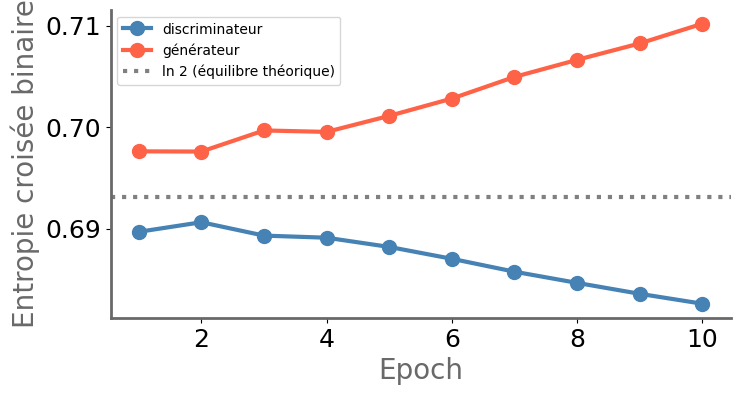

In [10]:
d_loss, g_loss = history.history['d_loss'], history.history['g_loss']
ep = np.arange(1, len(d_loss) + 1)

plt.figure(figsize=(8, 4))
plt.plot(ep, d_loss, 'o-', label='discriminateur')
plt.plot(ep, g_loss, 'o-', label='générateur')
plt.axhline(np.log(2), color='grey', ls=':', label='ln 2 (équilibre théorique)')
plt.xlabel('Epoch'); plt.ylabel('Entropie croisée binaire'); plt.legend()
fidle.scrawler.save_fig('03-losses')
plt.show()

**Lecture des courbes.** Dans un GAN, les pertes ne mesurent pas la qualité des images : elles indiquent l'équilibre entre les deux réseaux. Ici, les deux restent très proches de ln 2 ≈ 0,693 pendant les 10 epochs (dans notre exécution, d_loss passe de 0,690 à 0,683 et g_loss de 0,698 à 0,710). Aucun des deux réseaux ne prend le contrôle, contrairement à l'expérience de contrôle où d_loss tombait à 0 en quelques centaines de batchs.

La pente est toutefois régulière : le discriminateur gagne un peu de terrain à chaque epoch. Prolonger beaucoup l'entraînement risquerait de faire revenir le déséquilibre observé plus haut. C'est une raison de ne pas dépasser une dizaine d'epochs.

### Sauvegarde du modèle

La méthode `save` de `DCGAN` enregistre le générateur et le discriminateur dans deux fichiers `.h5`.

In [11]:
gan.save(f'{run_dir}/models/model.h5')
print(sorted(os.listdir(f'{run_dir}/models')))

['model-discriminator.h5', 'model-generator.h5']


### Images produites pendant l'entraînement

Une ligne par epoch, de la première (en haut) à la dernière (en bas), avec 12 images chacune. Les vecteurs latents sont tirés au hasard à chaque epoch : on suit la qualité générale, pas l'évolution d'une même image.

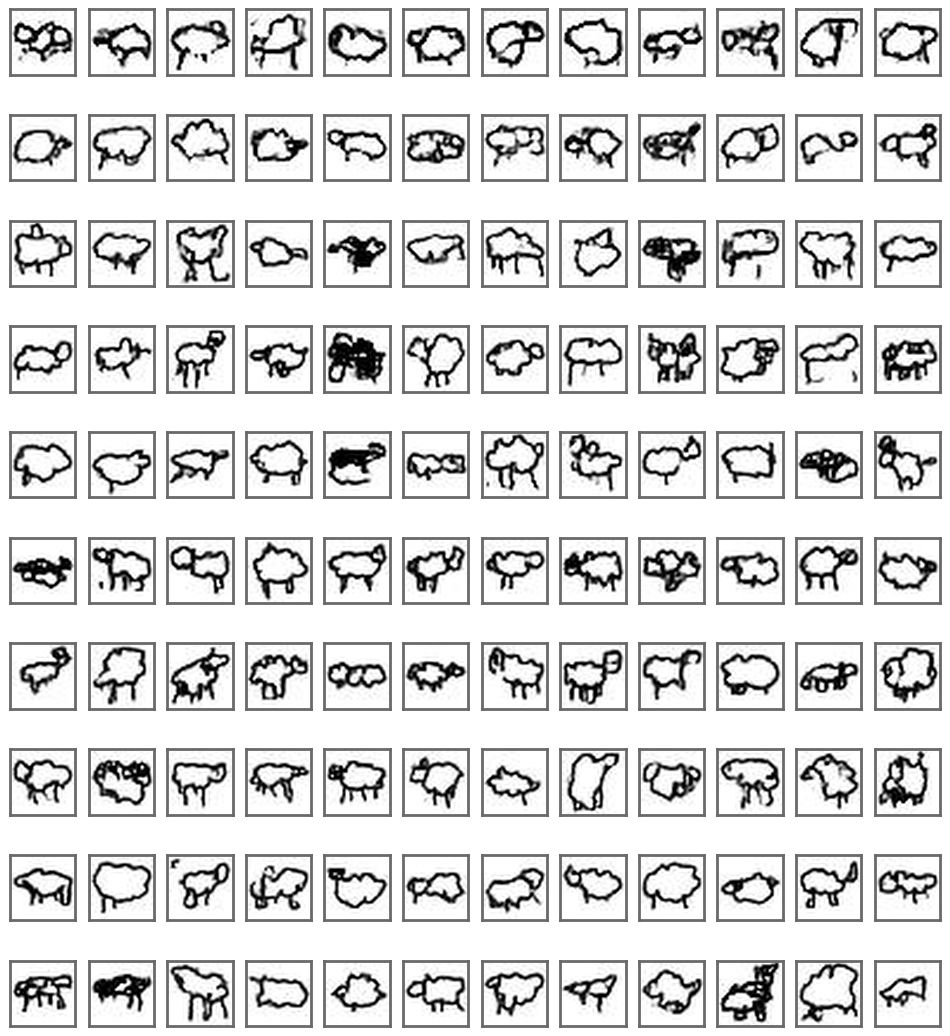

In [12]:
images = []
for epoch in range(0, epochs, 1):
    for i in range(num_img):
        filename = f'{run_dir}/images/image-{epoch:03d}-{i:02d}.jpg'
        image = io.imread(filename)
        images.append(image)

fidle.scrawler.images(np.array(images), columns=num_img, x_size=1, y_size=1, save_as='04-epochs')

**Choix du nombre d'epochs.** Dès la première epoch, les images ressemblent à des moutons, avec un corps arrondi et des pattes, mais les traits sont flous et parfois bruités. Ils deviennent plus nets et plus continus au fil des epochs. Sur un essai de 15 epochs avec la même configuration, l'amélioration visuelle devient marginale après la 8e ou 9e epoch. Nous avons donc retenu **10 epochs** (environ 6 à 7 minutes sur une RTX 4070 Ti) : c'est le bon compromis entre la netteté des traits et la lente dérive des pertes vue plus haut.

## Étape 5 — Génération

On recharge le modèle depuis le disque (indépendamment de l'objet entraîné), puis on tire des vecteurs latents selon une loi normale $\mathcal{N}(0, I)$, la même que pendant l'entraînement.

Fidle DCGAN is ready :-)  latent dim = 128


Reloaded.


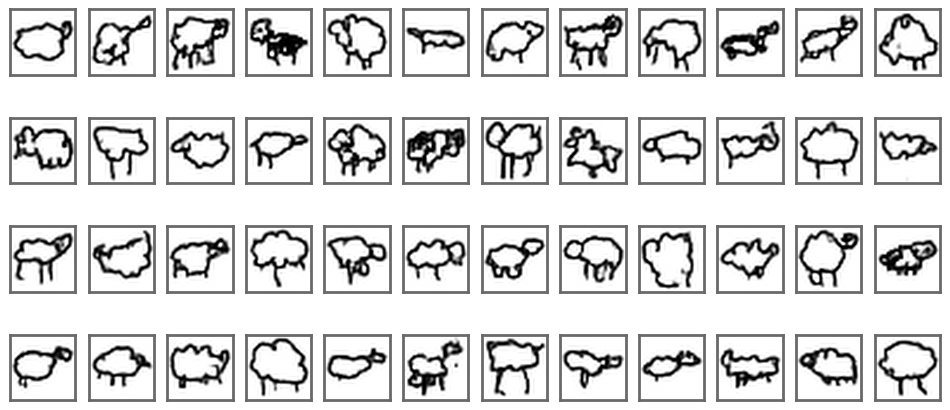

In [13]:
gan = DCGAN(latent_dim=latent_dim)
gan.reload(f'{run_dir}/models/model.h5')

z = np.random.normal(size=(48, latent_dim))
generated = gan.generator.predict(z, verbose=0)

fidle.scrawler.images(generated, columns=12, x_size=1, y_size=1, save_as='05-generated')

## Analyse des images générées

L'inspection visuelle est complétée par trois vérifications simples :

1. **Avis du discriminateur.** Score moyen $D(x)$ sur des images réelles et générées. Un score proche de 0,5 pour les deux indique que le discriminateur ne sait plus les distinguer.
2. **Quantité de trait.** Proportion de pixels « allumés » (> 0,5) dans les images réelles et générées. Un écart marqué signale des dessins trop chargés ou trop vides.
3. **Mémorisation.** Pour quelques images générées, on cherche l'image d'entraînement la plus proche (distance euclidienne sur les pixels). Si le plus proche voisin est quasiment identique, le générateur recopie au lieu de généraliser.

In [14]:
n = 2000
x_real = x_data[np.random.default_rng(1).choice(len(x_data), n, replace=False)]
x_fake = gan.generator.predict(np.random.normal(size=(n, latent_dim)), verbose=0)

d_real = gan.discriminator.predict(x_real, verbose=0).mean()
d_fake = gan.discriminator.predict(x_fake, verbose=0).mean()
print(f'D(réel)  moyen : {d_real:.3f}')
print(f'D(généré) moyen : {d_fake:.3f}')
print(f'Pixels de trait — réel : {(x_real > 0.5).mean():.1%}   généré : {(x_fake > 0.5).mean():.1%}')

D(réel)  moyen : 0.495
D(généré) moyen : 0.481
Pixels de trait — réel : 17.8%   généré : 16.9%


Distance au plus proche voisin : [7.7 7.5 7.  8.2 7.4 9.1 7.5 7.3 8.5 8.3 5.5 6.5]
Référence réel → réel        : [6.9 8.1 7.3 5.9 6.4 6.8 6.8 6.4 7.4 5.2 9.1 4.3]


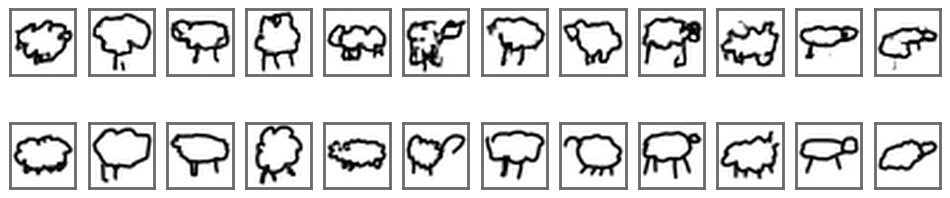

In [15]:
def nearest_neighbours(queries, data, batch=20000):
    q = tf.reshape(tf.constant(queries), (len(queries), -1))
    q2 = tf.reduce_sum(q * q, axis=1, keepdims=True)
    best_d, best_i = np.full(len(queries), np.inf), np.zeros(len(queries), int)
    for s in range(0, len(data), batch):
        d = tf.reshape(tf.constant(data[s:s + batch]), (-1, q.shape[1]))
        dist = (q2 - 2 * tf.matmul(q, d, transpose_b=True)
                + tf.reduce_sum(d * d, axis=1)[None, :]).numpy()
        i = dist.argmin(axis=1)
        m = dist[np.arange(len(queries)), i] < best_d
        best_d[m], best_i[m] = dist[np.arange(len(queries)), i][m], i[m] + s
    return best_i, np.sqrt(np.maximum(best_d, 0))

queries = x_fake[:12]
idx, dist = nearest_neighbours(queries, x_data)
print('Distance au plus proche voisin :', np.round(dist, 1))

# Distance typique entre une image réelle et son plus proche voisin (hors elle-même), pour référence
_, dist_ref = nearest_neighbours(x_data[:12], x_data[12:])
print('Référence réel → réel        :', np.round(dist_ref, 1))

fidle.scrawler.images(np.concatenate([queries, x_data[idx]]), columns=12, x_size=1, y_size=1,
                      save_as='06-nearest')

*Ligne du haut : images générées. Ligne du bas : leur plus proche voisin dans le jeu d'entraînement.*


## Conclusion

**Ce qui fonctionne**
- La plupart des images générées sont des moutons reconnaissables : corps « nuageux », tête sur le côté, deux à quatre pattes, avec un style de trait proche des dessins Quick Draw.
- Les poses et formes sont variées (profil gauche ou droit, corps rond ou allongé, avec ou sans tête), sans effondrement de mode visible : le générateur ne produit pas toujours le même dessin.
- Le discriminateur final donne un score proche de 0,5 aux images réelles comme aux images générées (0,495 et 0,481 dans notre exécution). La proportion de trait est presque la même (17,8 % contre 16,9 %).
- Le générateur ne recopie pas les données. La distance de chaque image générée à son plus proche voisin réel est du même ordre que celle entre deux dessins réels (≈ 5 à 9), et les voisins trouvés partagent la pose mais pas le tracé.

**Limites**
- Certains échantillons restent ratés : amas de traits denses (gribouillis noircis), pattes qui flottent, contours ouverts ou fragmentés.
- L'évaluation reste surtout visuelle. Une mesure comme la FID demanderait un classifieur entraîné sur Quick Draw pour être pertinente sur des images 28×28 en traits.
- Avec le `train_step` fourni, le Dropout du discriminateur n'est jamais actif. La stabilité vient uniquement de l'écart entre les taux d'apprentissage.

**Point clé de cette partie.** L'architecture demandée par l'énoncé n'apprend que si le discriminateur est nettement plus lent que le générateur (2e-5 contre 2e-4). Avec des taux égaux, le générateur produit des images vides en moins de 300 batchs, pour une raison identifiable : un fond majoritairement noir, combiné à la saturation de la sigmoid de sortie.
